## Catalogues
This notebook looks at the table **planed CMIP6 EURO-CORDEX EUR-12**
and compares it with the **catalogue about the available data at the Jülich server**

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import intake
import pandas as pd
import os

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [ ]:
# URL to the CMIP6 downscaling plans CSV file (Jesus Table)
# also have a look here:
# https://wcrp-cordex.github.io/simulation-status/CORDEX_CMIP6_status.html#EUR-12

url = "https://raw.githubusercontent.com/WCRP-CORDEX/simulation-status/main/CMIP6_downscaling_plans.csv"
df = pd.read_csv(url)
df.head()
#
df.columns

Index(['domain_id', 'institution_id', 'contact', 'source_id',
       'driving_source_id', 'driving_variant_label', 'driving_experiment_id',
       'status', 'estimated_completion_date', 'comments'],
      dtype='str')

In [22]:
df_eurbalanced = df.loc[
    df["comments"].str.contains("#EURbalanced", na=False, regex=False)
].copy()

df_eurbalanced['driving_source_id'].unique()
df['domain_id'].unique()

<ArrowStringArray>
[ 'AFR-12',  'AFR-18',  'ANT-12',  'ARC-12',  'AUS-12', 'AUS-20i',  'AUS-25',
  'CAM-12',  'CAM-18',  'CAM-25',  'CAS-12',  'EAS-12',  'EAS-25',  'EUR-12',
  'MED-12',  'MED-25',  'NAM-12',  'NAM-25', 'MENA-25',  'SAM-12',  'SAM-25',
  'SEA-12',  'SEA-25',  'WAS-12',  'WAS-18',  'WAS-25']
Length: 26, dtype: str

### Select what I need from planed simulations e.g. EUR-12

In [ ]:
df_eur12=df[df['domain_id']=='EUR-12']
# This is the selection of EURO-CORDEX data within the EUR-12 domain
df_eur12=df_eur12[df_eur12['institution_id']!='EURO-CORDEX']
df_eur12.head()
df_eur12_small = df_eur12[['institution_id', 'source_id', 'driving_source_id', 'driving_variant_label', 'driving_experiment_id','comments']]
# we only want historical and ssps:
df_eur12_small=df_eur12_small[df_eur12_small['driving_source_id']!='ERA5']
df_eur12_small.to_csv("df_eur12_small.csv", index=False)
df_eur12_small.head()

,institution_id,source_id,driving_source_id,driving_variant_label,driving_experiment_id,comments
336,AUTH,WRF451Q,MPI-ESM1-2-HR,r1i1p1f1,historical,#EURbalanced #ManySSP #CORDEX-CORE
337,AUTH,WRF451Q,MPI-ESM1-2-HR,r1i1p1f1,ssp126,#EURbalanced #ManySSP
338,BCCR-UCAN,WRF451Q,NorESM2-MM,r1i1p1f1,historical,#EURbalanced #CORDEX-CORE
339,BCCR-UCAN,WRF451Q,NorESM2-MM,r1i1p1f1,ssp126,#EURbalanced
340,BCCR-UCAN,WRF451Q,NorESM2-MM,r1i1p1f1,ssp370,#EURbalanced #CORDEX-CORE


### Available in Jülich

In [36]:
cat = intake.open_esm_datastore("https://raw.githubusercontent.com/euro-cordex/jsc-cordex-catalog/refs/heads/main/CORDEX-CMIP6-JSC.json")
#cat#.keys()

### Available, but wrong format

In [7]:
# perhaps also available in Jülich, but only wrong format:
# failed parsing entries
url_not="https://raw.githubusercontent.com/euro-cordex/jsc-cordex-catalog/main/failed_parsing.csv"
print(url_not)
failed_df = pd.read_csv(url_not)
list=failed_df["path"].apply(os.path.basename)
day_files = list[list.str.contains("day", case=False, na=False)]
day_files = day_files.str.replace(
    r"(?i)(day).*",
    r"\1",
    regex=True
)

day_files.unique()


https://raw.githubusercontent.com/euro-cordex/jsc-cordex-catalog/main/failed_parsing.csv


<ArrowStringArray>
[       'vas_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
       'huss_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
        'tas_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
    'sfcWind_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
       'rsds_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
        'uas_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
        'clt_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
 'sfcWindmax_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
     'tasmin_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
    'evspsbl_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
     'tasmax_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
       'rlds_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TAS

### Comparison of what is planned and what is available in the catalog

In [37]:
# This is the comparison of what is planned and what is available in the catalog
#
# ------------------------------------------------------------------
# CSV containing planned downscaling
# ------------------------------------------------------------------

df = pd.read_csv("df_eur12_small.csv")

# ------------------------------------------------------------------
# Intake-ESM Catalog with available simulations in Jülich
# ------------------------------------------------------------------

cat = intake.open_esm_datastore("https://raw.githubusercontent.com/euro-cordex/jsc-cordex-catalog/refs/heads/main/CORDEX-CMIP6-JSC.json")
cdf = cat.df

# ------------------------------------------------------------------
# Columns that together describe a model chain
# ------------------------------------------------------------------

match_cols = [
    "institution_id",
    "source_id",
    "driving_source_id",
    "driving_variant_label",
    "driving_experiment_id",
]

# ------------------------------------------------------------------
# Required variables
# ------------------------------------------------------------------

required_vars = {"tas", "pr"}
#required_vars = {"tas", "pr", "tasmin", "tasmax"}

# ------------------------------------------------------------------
# Only consider daily data
# ------------------------------------------------------------------

cdf_day = cdf[cdf["frequency"] == "day"]

# ------------------------------------------------------------------
# Which variables are available for each model chain?
# ------------------------------------------------------------------

available = (
    cdf_day.groupby(match_cols)["variable_id"]
    .agg(lambda x: set(x))
    .reset_index()
)

# ------------------------------------------------------------------
# Are all required variables available?
# ------------------------------------------------------------------

available["in_catalog"] = available["variable_id"].apply(
    lambda x: required_vars.issubset(set(x))
)

# ------------------------------------------------------------------
# Which variables are missing?
# ------------------------------------------------------------------

available["missing_variables"] = available["variable_id"].apply(
    lambda x: ",".join(sorted(required_vars - set(x))))


# ------------------------------------------------------------------
# Merge with the original CSV
# ------------------------------------------------------------------

df = df.merge(
    available,
    on=match_cols,
    how="left"
)

# ------------------------------------------------------------------
# Combination not found in the catalog
# ------------------------------------------------------------------

df["in_catalog"] = df["in_catalog"].fillna(False)

df["missing_variables"] = df["missing_variables"].fillna(
    "combination_not_found"
)

# ------------------------------------------------------------------
# Convert True/False to yes/no
# ------------------------------------------------------------------

df["in_catalog"] = df["in_catalog"].map(
    {True: "yes", False: "no"}
)

# ------------------------------------------------------------------
# Save
# ------------------------------------------------------------------

df.to_csv(
    "CMIP6_downscaling_plans_checked.csv",
    index=False
)

print(df["in_catalog"].value_counts())

in_catalog
no     106
yes     72
Name: count, dtype: int64


# select balanced matrix

In [48]:
df = pd.read_csv("CMIP6_downscaling_plans_checked.csv")

# only balance matrix
df_eurbalanced = df.loc[
    df["comments"].str.contains("#EURbalanced", na=False, regex=False)
].copy()

df_eurbalanced['driving_source_id'].unique()


<ArrowStringArray>
['MPI-ESM1-2-HR',    'NorESM2-MM',        'MIROC6',  'CMCC-CM2-SR5',
 'EC-Earth3-Veg',   'CNRM-ESM2-1']
Length: 6, dtype: str

# Create plots

In [49]:
# Just for fancy plots, I like to high light the simulations of the balanced matrix
# or you aloso have only the simulations from the balance matrix

df_eurbalanced["gcm_variant"] = (
    df_eurbalanced["driving_source_id"]
    + "\n"
    + df_eurbalanced["driving_variant_label"]
)
selected_variants = df_eurbalanced["gcm_variant"].unique()
selected_variants


<ArrowStringArray>
['MPI-ESM1-2-HR\nr1i1p1f1',    'NorESM2-MM\nr1i1p1f1',
        'MIROC6\nr1i1p1f1',  'CMCC-CM2-SR5\nr1i1p1f1',
 'EC-Earth3-Veg\nr1i1p1f1',   'CNRM-ESM2-1\nr1i1p1f2']
Length: 6, dtype: str

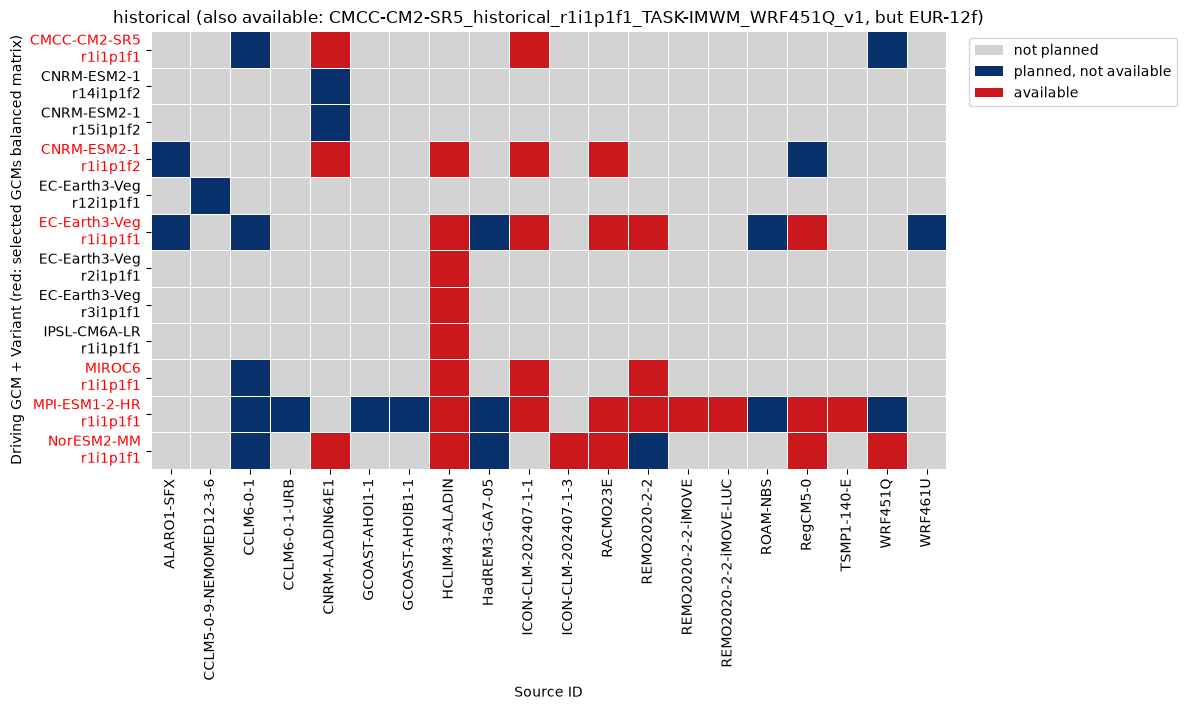

<Figure size 640x480 with 0 Axes>

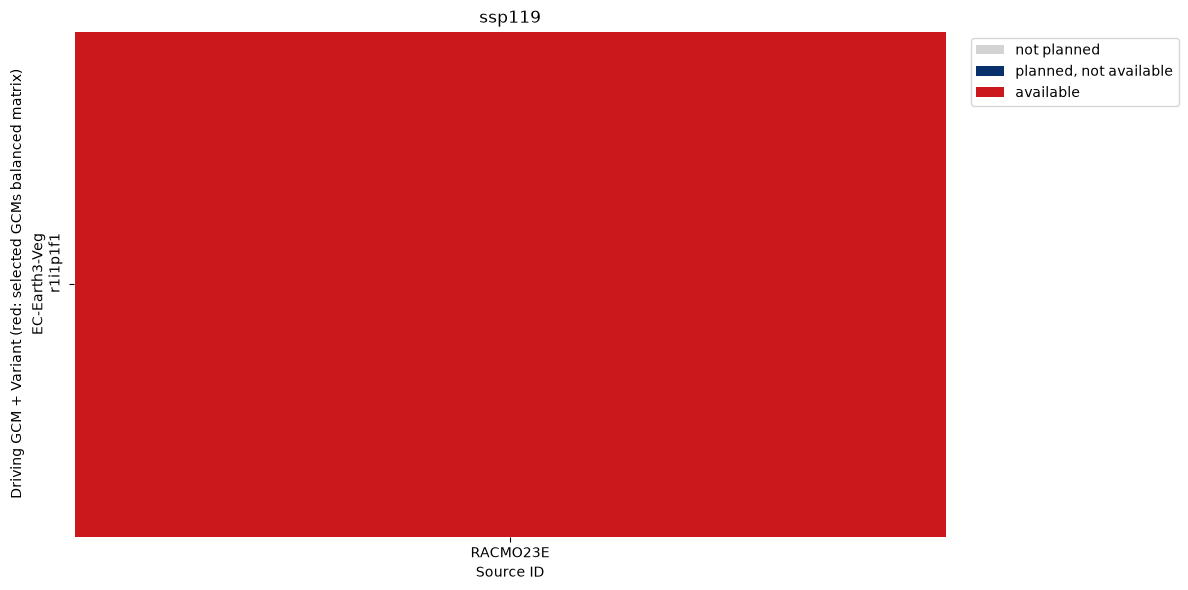

<Figure size 640x480 with 0 Axes>

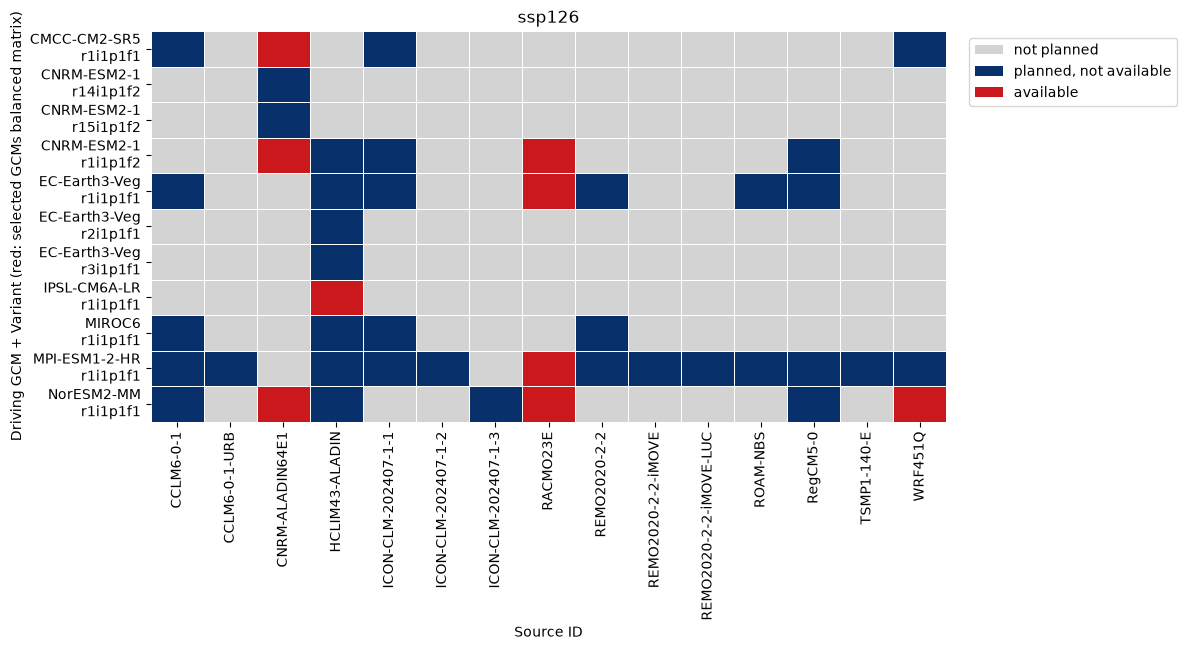

<Figure size 640x480 with 0 Axes>

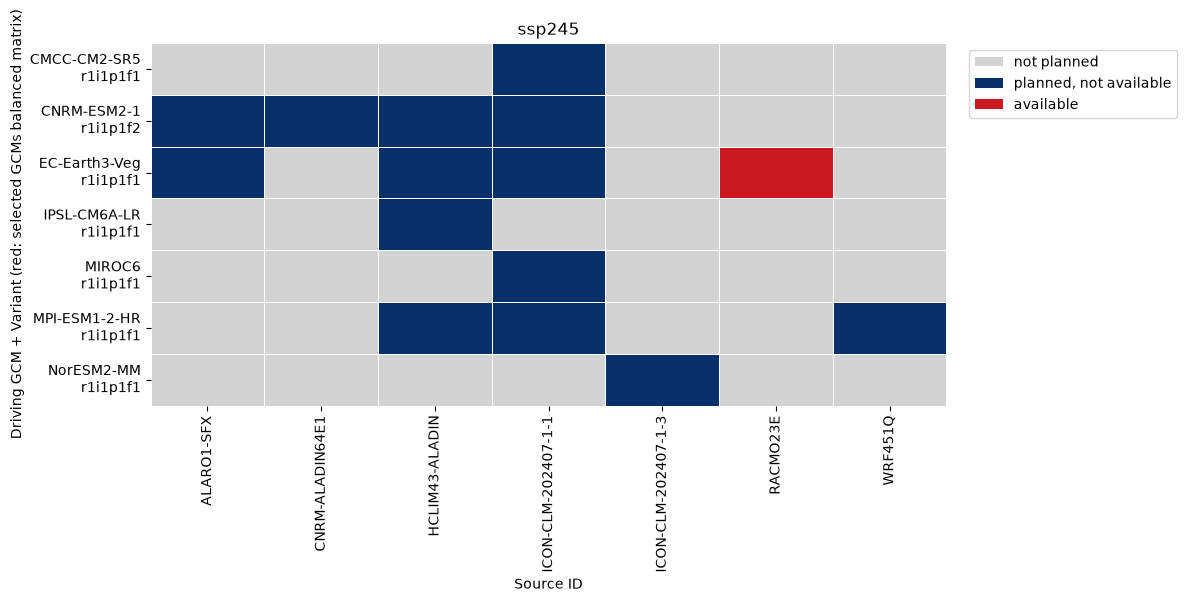

<Figure size 640x480 with 0 Axes>

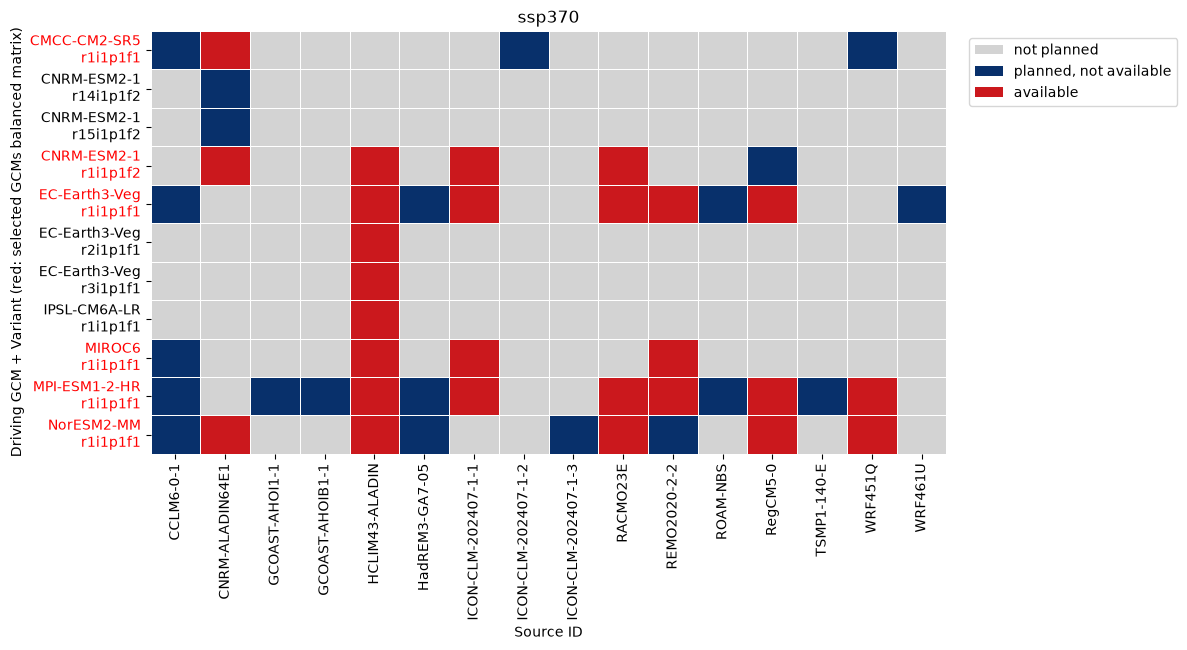

<Figure size 640x480 with 0 Axes>

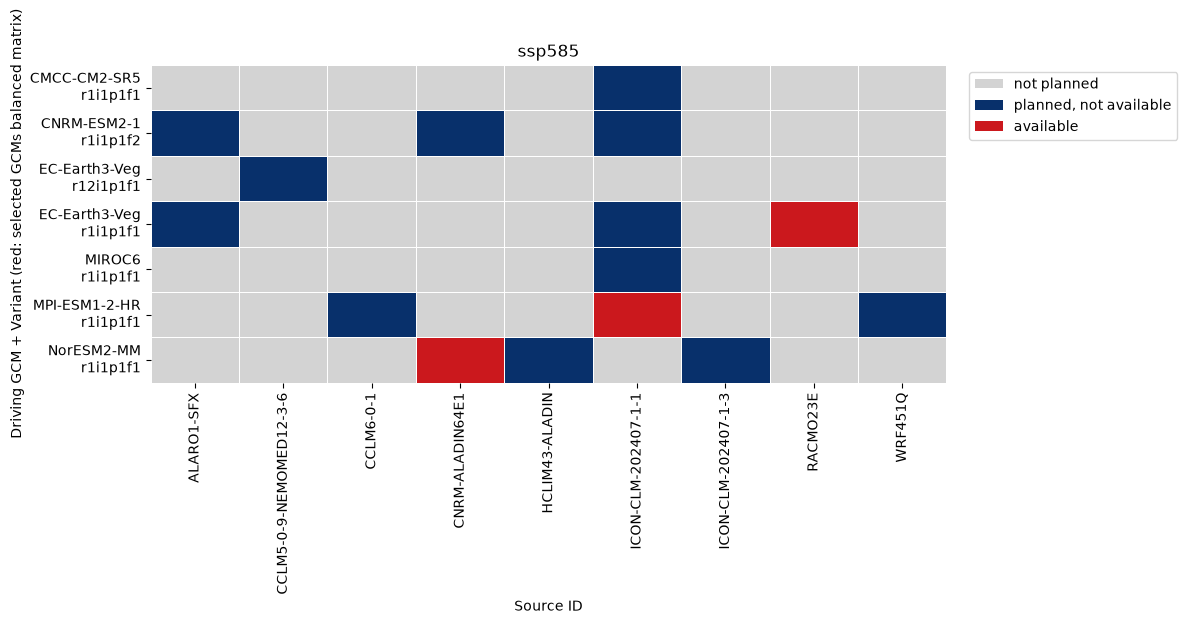

<Figure size 640x480 with 0 Axes>

In [50]:
# Plotting the heatmaps for the CMIP6 downscaling plans
# Already loaded the CSV into the dataframe `df`
df = pd.read_csv("CMIP6_downscaling_plans_checked.csv")

# Kombination für x-Achse erzeugen
df["gcm_variant"] = (
    df["driving_source_id"]
    + "\n"
    + df["driving_variant_label"]
)

# yes/no in 1/0 umwandeln
df["value"] = df["in_catalog"].map({
    "yes": 2,
    "no": 1
})

# Farben:
from matplotlib.colors import ListedColormap

cmap = ListedColormap([
    "lightgrey",  # 0 = not in CSV
    "#08306B",    # 1 = no (blue)
    "#CB181D",    # 2 = yes (red)
])

for experiment in sorted(df["driving_experiment_id"].unique()):

    sub = df[df["driving_experiment_id"] == experiment]

    heatmap_df = sub.pivot_table(
        index="gcm_variant",
        columns="source_id",
        values="value",
        aggfunc="max",
        fill_value=0
    )

    plt.figure(
        figsize=(
            max(12, len(heatmap_df.columns) * 0.4),
            max(6, len(heatmap_df.index) * 0.6)
        )
    )

    sns.heatmap(
        heatmap_df,
        cmap=cmap,
        cbar=False,
        linewidths=0.5,
        linecolor="white",
        vmin=0,
        vmax=2
    )
    if experiment in ["historical", "ssp370"]:  # example of multiple experiments to highlight
        ax = plt.gca()
        for label in ax.get_yticklabels():
            if label.get_text() in selected_variants:
                label.set_color("red")
    if experiment in ["historical"]:
        title = f"{experiment} (also available: CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1, but EUR-12f)"
    else:
        title = f"{experiment}"
    plt.title(title)
    plt.ylabel("Driving GCM + Variant (red: selected GCMs balanced matrix)")
    plt.xlabel("Source ID")

    from matplotlib.patches import Patch

    legend_elements = [
        Patch(facecolor="lightgrey", label="not planned"),
        Patch(facecolor="#08306B", label="planned, not available"),
        Patch(facecolor="#CB181D", label="available"),
    ]


    plt.legend(
        handles=legend_elements,
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

    plt.savefig(
        f"heatmap_{experiment}.png",
        dpi=300,
        bbox_inches="tight"
    )

# Balanced Matrix

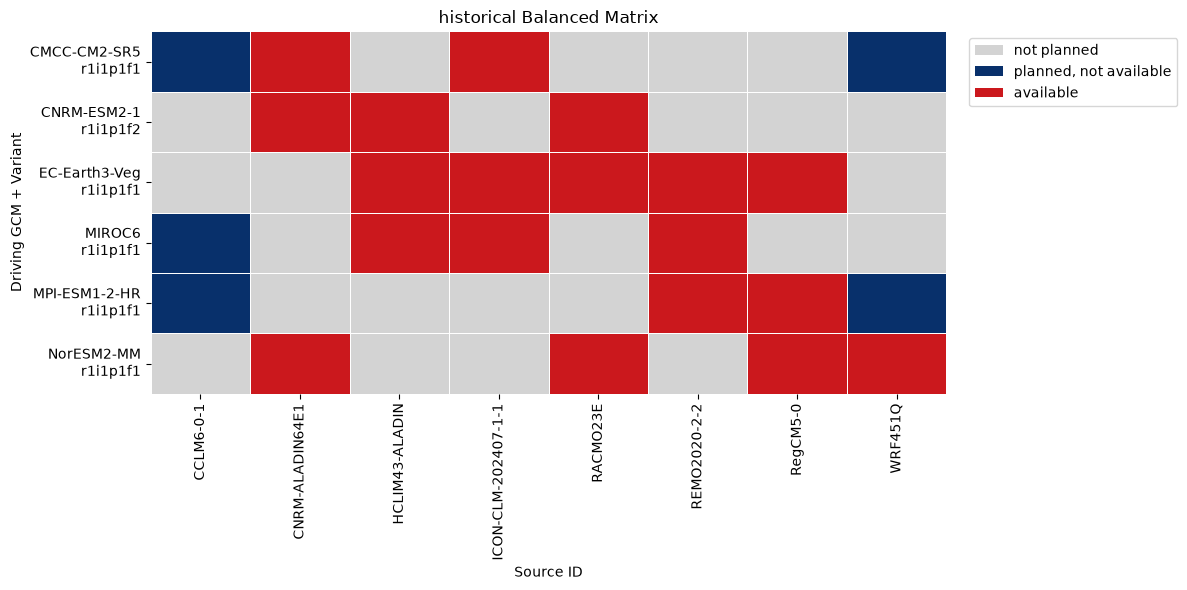

<Figure size 640x480 with 0 Axes>

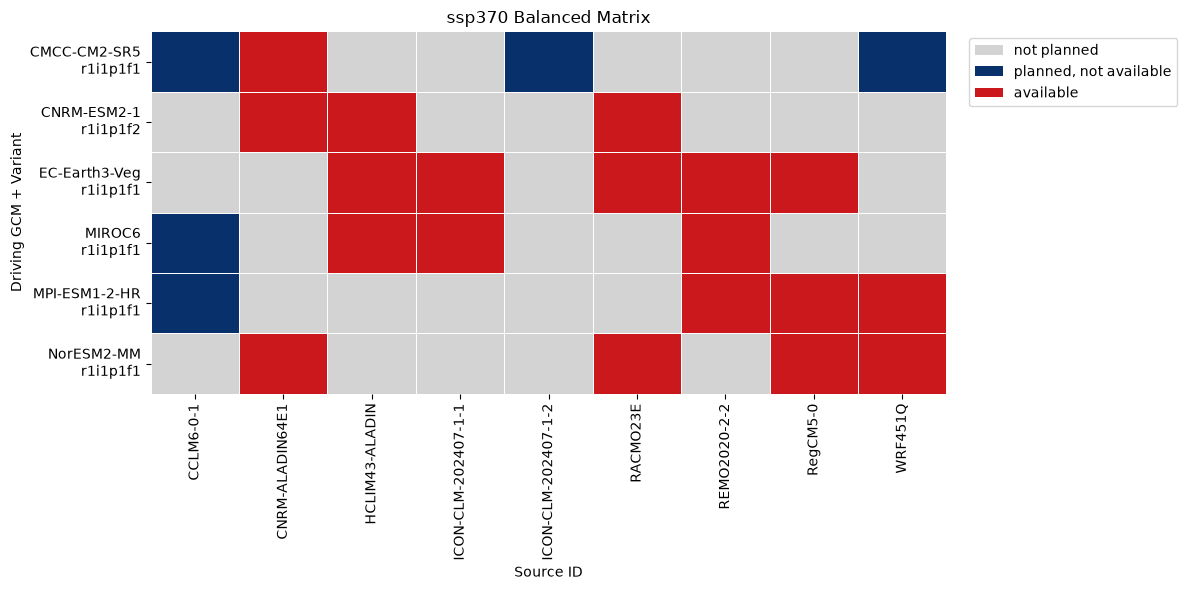

<Figure size 640x480 with 0 Axes>

In [52]:
# plot just balanced matrix:
df_bm = df_eurbalanced
# Kombination für x-Achse erzeugen
df_bm["gcm_variant"] = (
    df_bm["driving_source_id"]
    + "\n"
    + df_bm["driving_variant_label"]
)

# yes/no in 1/0 umwandeln
df_bm["value"] = df_bm["in_catalog"].map({
    "yes": 2,
    "no": 1
})

# Farben:
from matplotlib.colors import ListedColormap

cmap = ListedColormap([
    "lightgrey",  # 0 = not in CSV
    "#08306B",    # 1 = no (blue)
    "#CB181D",    # 2 = yes (red)
])

for experiment in ['historical', 'ssp370'] : #sorted(df_bm["driving_experiment_id"].unique()):

    sub = df_bm[df_bm["driving_experiment_id"] == experiment]

    heatmap_df = sub.pivot_table(
        index="gcm_variant",
        columns="source_id",
        values="value",
        aggfunc="max",
        fill_value=0
    )

    plt.figure(
        figsize=(
            max(12, len(heatmap_df.columns) * 0.4),
            max(6, len(heatmap_df.index) * 0.6)
        )
    )

    sns.heatmap(
        heatmap_df,
        cmap=cmap,
        cbar=False,
        linewidths=0.5,
        linecolor="white",
        vmin=0,
        vmax=2
    )
    
    title = f"{experiment} Balanced Matrix"
    plt.title(title)
    plt.ylabel("Driving GCM + Variant")
    plt.xlabel("Source ID")

    from matplotlib.patches import Patch

    legend_elements = [
        Patch(facecolor="lightgrey", label="not planned"),
        Patch(facecolor="#08306B", label="planned, not available"),
        Patch(facecolor="#CB181D", label="available"),
    ]

    plt.legend(
        handles=legend_elements,
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

    plt.savefig(
        f"heatmap_{experiment}_balance_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

